# 02 · Modelo 2 — Zonas críticas de acessibilidade (agrupamento)

**Projeto:** Waze da Acessibilidade · Global Solution 2026/2 · CitizenTech
**Disciplina:** Artificial Intelligence & Chatbot

## 1. Entendimento do problema

Cada relato autenticado pelo **Modelo 1** vira um ponto no mapa: latitude, longitude e tipo de obstáculo.
Com centenas de pontos, a pergunta passa a ser: **onde estão as áreas com muitos obstáculos**, que as rotas devem evitar ou sinalizar?

O **Modelo 2** responde isso com **agrupamento** (aprendizado **não supervisionado**: não existe uma "resposta certa" para ensinar ao modelo; ele encontra os grupos sozinho).

| Etapa | O que fazemos |
|---|---|
| Agrupar | Juntar relatos **próximos no mapa** em zonas |
| Descrever | Para cada zona: onde fica, quantos obstáculos, de quais tipos |
| Classificar | Dar um **nível de criticidade** (Alta, Média ou Baixa) para cada zona |
| Usar no app | Dado um ponto da rota, dizer se ele está em uma zona crítica e qual o nível |

**Quem ganha com isso:** um cadeirante que planeja ir da Sé até a Liberdade recebe uma rota que **contorna** a zona de criticidade alta, ou pelo menos um aviso antes de entrar nela.

> ⚠️ **Origem dos dados:** a base `relatos_obstaculos.csv` é **sintética**, gerada no notebook `00_gerar_base_relatos.ipynb` com coordenadas reais de 7 bairros de São Paulo e 6 focos de problemas definidos por nós (detalhes no notebook 00 e no arquivo `integrantes.txt`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

SEMENTE = 42
np.random.seed(SEMENTE)

PASTA_DADOS = "../dados"
PASTA_MODELOS = "../modelos"

TIPOS = ["buraco", "calcada_irregular", "escada_sem_rampa", "obstrucao_calcada"]
CORES = dict(zip(TIPOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
CORES_NIVEL = {"Alta": "#d03b3b", "Média": "#ec835a", "Baixa": "#fab219"}
sns.set_theme(style="whitegrid")

## 2. Análise exploratória

In [2]:
df = pd.read_csv(os.path.join(PASTA_DADOS, "relatos_obstaculos.csv"))
print("Linhas:", len(df), "| Colunas:", list(df.columns))
df.head()

Linhas: 1132 | Colunas: ['id', 'latitude', 'longitude', 'tipo_obstaculo', 'data_relato', 'bairro']


,id,latitude,longitude,tipo_obstaculo,data_relato,bairro
0,1,-23.556590,-46.634622,buraco,2026-10-20,Liberdade
1,2,-23.588687,-46.633594,calcada_irregular,2026-10-27,Vila Mariana
2,3,-23.551175,-46.635895,calcada_irregular,2026-01-14,Sé
3,4,-23.557662,-46.645123,escada_sem_rampa,2026-03-26,Bela Vista
4,5,-23.555621,-46.633408,calcada_irregular,2026-10-28,Liberdade


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1132 entries, 0 to 1131
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              1132 non-null   int64  
 1   latitude        1132 non-null   float64
 2   longitude       1132 non-null   float64
 3   tipo_obstaculo  1132 non-null   str    
 4   data_relato     1132 non-null   str    
 5   bairro          1112 non-null   str    
dtypes: float64(2), int64(1), str(3)
memory usage: 53.2 KB


In [4]:
df.describe().round(4)

,id,latitude,longitude
count,1132.0000,1132.0000,1132.0000
mean,566.5000,-23.5586,-46.6476
std,326.9246,0.0144,0.0230
min,1.0000,-23.5947,-46.6999
25%,283.7500,-23.5665,-46.6468
50%,566.5000,-23.5561,-46.6355
75%,849.2500,-23.5487,-46.6326
max,1132.0000,-23.5380,-46.6253


### 2.1 Qualidade dos dados

In [5]:
print("Valores vazios por coluna:")
print(df.isna().sum(), "\n")

# relato duplicado = mesmo ponto, mesmo tipo e mesma data (ignorando o id)
colunas_relato = ["latitude", "longitude", "tipo_obstaculo", "data_relato"]
print("Relatos duplicados:", df.duplicated(subset=colunas_relato).sum())

fora = df[(df["latitude"].abs() > 90) | (df["longitude"].abs() > 180)]
print("Coordenadas impossíveis:", len(fora))

Valores vazios por coluna:
id                 0
latitude           0
longitude          0
tipo_obstaculo     0
data_relato        0
bairro            20
dtype: int64 

Relatos duplicados: 15
Coordenadas impossíveis: 0


**Insight:** a base tem **15 relatos duplicados** (a mesma pessoa enviando o mesmo obstáculo duas vezes) e **20 relatos sem bairro**. Isso é comum em dados reais e será tratado na preparação.
Não há coordenadas impossíveis.

### 2.2 Distribuição dos tipos de obstáculo

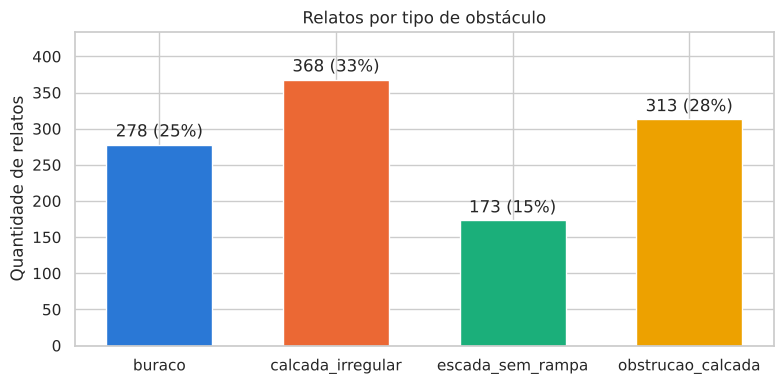

In [6]:
contagem = df["tipo_obstaculo"].value_counts().reindex(TIPOS)

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(contagem.index, contagem.values, color=[CORES[t] for t in contagem.index], width=0.6)
ax.bar_label(barras, labels=[f"{v} ({v / contagem.sum():.0%})" for v in contagem.values], padding=3)
ax.set_ylim(0, contagem.max() * 1.18)
ax.set_title("Relatos por tipo de obstáculo")
ax.set_ylabel("Quantidade de relatos")
plt.tight_layout()
plt.show()

**Insight:** **calçada irregular** e **obstrução da calçada** são os problemas mais relatados, juntos mais de 60% dos relatos.
Escada sem rampa é o tipo menos frequente, mas é o mais grave para um cadeirante (é uma barreira **intransponível**). Por isso, na criticidade, o tipo terá um **peso** e não vamos olhar só a quantidade.

### 2.3 Relatos por bairro

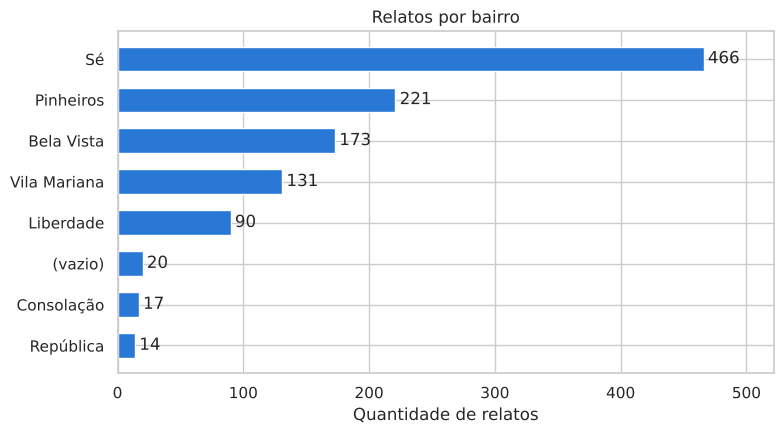

In [7]:
por_bairro = df["bairro"].fillna("(vazio)").value_counts()

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.barh(por_bairro.index, por_bairro.values, color="#2a78d6", height=0.6)
ax.bar_label(barras, padding=3)
ax.invert_yaxis()
ax.set_xlim(0, por_bairro.max() * 1.12)
ax.set_title("Relatos por bairro")
ax.set_xlabel("Quantidade de relatos")
plt.tight_layout()
plt.show()

In [8]:
# tipos de obstáculo dentro de cada bairro (% das linhas)
tabela = pd.crosstab(df["bairro"], df["tipo_obstaculo"], normalize="index").reindex(columns=TIPOS)
tabela.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

tipo_obstaculo,buraco,calcada_irregular,escada_sem_rampa,obstrucao_calcada
bairro,,,,
Bela Vista,13%,29%,46%,12%
Consolação,29%,53%,6%,12%
Liberdade,19%,29%,29%,23%
Pinheiros,46%,24%,7%,23%
República,21%,36%,7%,36%
Sé,19%,31%,9%,41%
Vila Mariana,27%,54%,6%,13%


**Insights:**
- **Sé** concentra o maior número de relatos (o bairro inclui a Praça da Sé e a Rua 25 de Março, com muito comércio de rua). A **obstrução da calçada** domina ali.
- **Bela Vista** tem a maior proporção de **escadas sem rampa** (região do Bixiga, com escadarias e ladeiras).
- **Pinheiros** tem a maior proporção de **buracos** (região do Largo da Batata).
- **Consolação** e **República** têm poucos relatos: são obstáculos isolados, sem um foco claro.

### 2.4 Os relatos no mapa

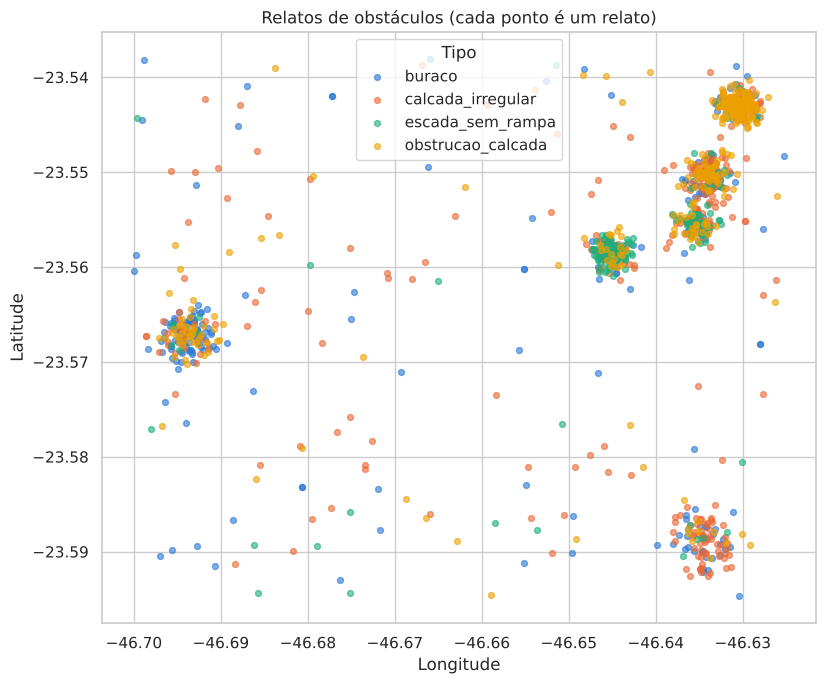

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
for tipo in TIPOS:
    parte = df[df["tipo_obstaculo"] == tipo]
    ax.scatter(parte["longitude"], parte["latitude"], s=18, alpha=0.6, color=CORES[tipo], label=tipo)
ax.set_title("Relatos de obstáculos (cada ponto é um relato)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Tipo")
ax.set_aspect(1 / np.cos(np.radians(-23.56)))  # deixa o mapa sem distorção
plt.tight_layout()
plt.show()

**Insight:** dá para ver **concentrações claras** de pontos (os focos), e entre elas há pontos espalhados (obstáculos isolados).
Esse é exatamente o padrão que um algoritmo de agrupamento consegue encontrar. A pergunta seguinte é **quantos grupos** existem.

## 3. Preparação dos dados

1. **Remover duplicados:** um obstáculo relatado duas vezes não pode contar em dobro.
2. **Bairro vazio:** preenchemos com `"Não informado"`. O bairro **não entra no agrupamento** (usamos as coordenadas), então não precisamos descartar a linha.
3. **Escolha das variáveis:** usamos **apenas latitude e longitude**.
   - Uma "zona" é um **lugar no mapa**. Se o tipo entrasse no agrupamento, um buraco e uma escada **na mesma esquina** poderiam cair em grupos diferentes, e isso não faz sentido para a rota.
   - O **tipo** é usado **depois**, para descrever cada zona e calcular a gravidade.
4. **Padronização (`StandardScaler`):** deixa latitude e longitude na mesma escala (média 0, desvio 1). O K-Means usa distâncias, então nenhuma variável deve "pesar mais" só por causa da unidade.

In [10]:
antes = len(df)
df = df.drop_duplicates(subset=colunas_relato).reset_index(drop=True)
print("Duplicados removidos:", antes - len(df))

df["bairro"] = df["bairro"].fillna("Não informado")
print("Bairros vazios restantes:", df["bairro"].isna().sum())

X = df[["latitude", "longitude"]].values
print("Formato de X:", X.shape)

Duplicados removidos: 15
Bairros vazios restantes: 0
Formato de X: (1117, 2)


In [11]:
from sklearn.preprocessing import StandardScaler

escala = StandardScaler()
X_esc = escala.fit_transform(X)
print("Médias depois da padronização:", X_esc.mean(axis=0).round(3))
print("Desvios depois da padronização:", X_esc.std(axis=0).round(3))

Médias depois da padronização: [-0. -0.]
Desvios depois da padronização: [1. 1.]


## 4. Treinamento

Comparamos dois algoritmos de agrupamento:

| | **K-Means** | **DBSCAN** |
|---|---|---|
| Ideia | Divide os pontos em **k grupos**, cada um em volta de um centro | Junta pontos que têm **muitos vizinhos perto** |
| Precisa dizer o número de grupos? | Sim (escolhemos o **k**) | Não (escolhemos a distância `eps` e o mínimo de vizinhos) |
| Pontos isolados | Entram em algum grupo mesmo assim | Ficam marcados como **ruído** (-1) |
| Classifica um ponto **novo**? | **Sim** (`predict`) | Não tem `predict` |

### 4.1 K-Means: escolhendo o k (cotovelo e silhouette)
- **Método do cotovelo:** mostra a **inércia** (soma das distâncias dos pontos aos centros). Ela sempre cai quando o k aumenta; procuramos o ponto em que **para de cair muito** (o "cotovelo").
- **Silhouette score:** vai de -1 a 1 e mede se cada ponto está **mais perto do próprio grupo do que do grupo vizinho**. Quanto maior, mais bem separados os grupos.

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

METROS_POR_GRAU_LAT = 111_000
METROS_POR_GRAU_LON = 111_000 * np.cos(np.radians(-23.56))

def distancia_metros(lat1, lon1, lat2, lon2):
    # aproximação plana: suficiente para distâncias de poucos quilômetros
    return np.sqrt(((lat1 - lat2) * METROS_POR_GRAU_LAT) ** 2 + ((lon1 - lon2) * METROS_POR_GRAU_LON) ** 2)

valores_k = range(2, 13)
inercias, silhuetas, raios_medianos = [], [], []
for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE)
    grupos = km.fit_predict(X_esc)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_esc, grupos))
    # tamanho das zonas: distância (m) do centro que cobre 80% dos relatos de cada zona
    c = escala.inverse_transform(km.cluster_centers_)
    dist = distancia_metros(X[:, 0], X[:, 1], c[grupos, 0], c[grupos, 1])
    raios = [np.quantile(dist[grupos == g], 0.80) for g in range(k)]
    raios_medianos.append(np.median(raios))

resultado_k = pd.DataFrame({"k": list(valores_k), "inercia": inercias, "silhouette": silhuetas,
                            "raio_mediano_m": raios_medianos})
resultado_k.round(3)

,k,inercia,silhouette,raio_mediano_m
0,2,967.935,0.633,2587.638
1,3,351.655,0.739,1205.084
2,4,217.752,0.607,888.819
3,5,159.890,0.606,680.946
4,6,122.493,0.650,549.045
5,7,85.975,0.663,434.124
6,8,74.512,0.673,335.194
7,9,64.400,0.662,389.934
8,10,55.236,0.666,365.736
9,11,46.492,0.679,389.934


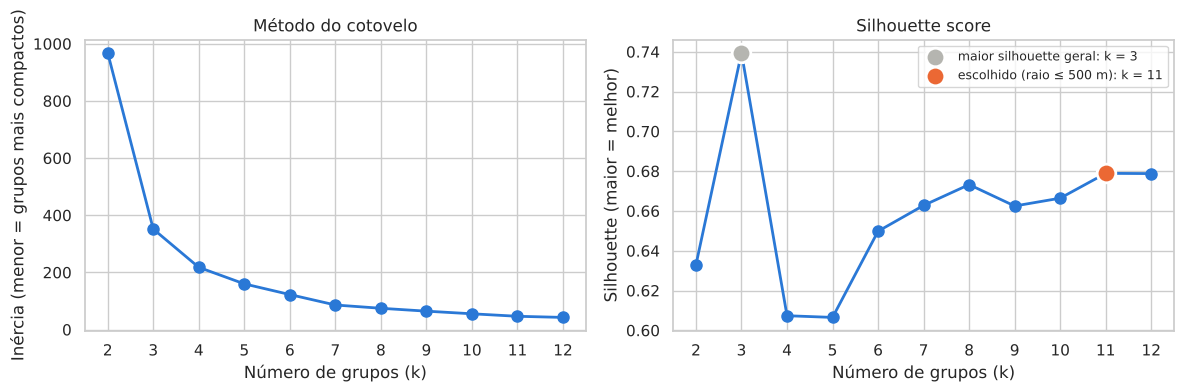

Maior silhouette geral: k = 3 (raio mediano 1205 m)
k escolhido: 11 | silhouette: 0.679 | raio mediano das zonas: 390 m


In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(resultado_k["k"], resultado_k["inercia"], color="#2a78d6", linewidth=2, marker="o", markersize=8)
ax1.set_title("Método do cotovelo")
ax1.set_xlabel("Número de grupos (k)")
ax1.set_ylabel("Inércia (menor = grupos mais compactos)")

ax2.plot(resultado_k["k"], resultado_k["silhouette"], color="#2a78d6", linewidth=2, marker="o", markersize=8)
pior_pratico = resultado_k.loc[resultado_k["silhouette"].idxmax()]
ax2.scatter([pior_pratico["k"]], [pior_pratico["silhouette"]], s=180, color="#b5b5b0", zorder=3,
            edgecolor="white", linewidth=2, label=f"maior silhouette geral: k = {int(pior_pratico['k'])}")
ax2.set_title("Silhouette score")
ax2.set_xlabel("Número de grupos (k)")
ax2.set_ylabel("Silhouette (maior = melhor)")

# regra prática (explicada abaixo): zonas com raio mediano de no máximo 500 m
RAIO_MAXIMO_M = 500
validos = resultado_k[resultado_k["raio_mediano_m"] <= RAIO_MAXIMO_M]
melhor = validos.loc[validos["silhouette"].idxmax()]
K = int(melhor["k"])
ax2.scatter([K], [melhor["silhouette"]], s=180, color="#eb6834", zorder=4, edgecolor="white", linewidth=2,
            label=f"escolhido (raio ≤ {RAIO_MAXIMO_M} m): k = {K}")
ax2.legend(loc="upper right", fontsize=9)

for ax in (ax1, ax2):
    ax.set_xticks(list(valores_k))
plt.tight_layout()
plt.show()

print(f"Maior silhouette geral: k = {int(pior_pratico['k'])} (raio mediano {pior_pratico['raio_mediano_m']:.0f} m)")
print(f"k escolhido: {K} | silhouette: {melhor['silhouette']:.3f} | raio mediano das zonas: {melhor['raio_mediano_m']:.0f} m")

**Insight importante: a métrica sozinha não basta.**
O maior silhouette **geral** está em um k pequeno (ponto cinza). Ele separa a cidade só em **grandes regiões** (centro, Pinheiros e Vila Mariana), cada uma com mais de 1 km de raio. Matematicamente os grupos ficam bem separados, mas **na prática não servem**: ninguém consegue "desviar" de uma área de 2 km a pé.

Por isso juntamos a métrica com uma **regra do problema**:
> Uma zona crítica deve ter **tamanho de caminhada**, com raio mediano de **no máximo 500 m** (cerca de 5 quarteirões).
> Entre os k que respeitam essa regra, escolhemos o de **maior silhouette** (ponto laranja).

**Resultado:** o k escolhido está na região do **cotovelo** (onde a inércia para de cair rápido) e tem um silhouette **acima de 0,6**, o que indica grupos bem definidos.
Com esse k, os focos do centro (25 de Março, Sé, Bixiga, Liberdade) deixam de ser uma "mancha" única e viram **zonas separadas**, cada uma com poucos quarteirões.

In [14]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMENTE)
df["zona"] = kmeans.fit_predict(X_esc)
sil_kmeans = silhouette_score(X_esc, df["zona"])
print(f"K-Means com k={K}: silhouette = {sil_kmeans:.3f}")
df["zona"].value_counts().sort_index()

K-Means com k=11: silhouette = 0.679


zona
0     137
1     169
2     110
3     236
4      19
5     172
6      30
7     189
8      17
9      15
10     23
Name: count, dtype: int64

### 4.2 DBSCAN
O DBSCAN tem dois parâmetros:
- `eps`: a distância máxima para dois pontos serem considerados "vizinhos" (na escala padronizada);
- `min_samples`: quantos vizinhos um ponto precisa ter para formar o "miolo" de um grupo.

Testamos alguns valores de `eps` e observamos quantos grupos e quanto ruído cada um gera.

In [15]:
from sklearn.cluster import DBSCAN

testes = []
for eps in [0.05, 0.08, 0.10, 0.12, 0.15, 0.20]:
    rotulos = DBSCAN(eps=eps, min_samples=10).fit_predict(X_esc)
    n_grupos = len(set(rotulos)) - (1 if -1 in rotulos else 0)
    ruido = (rotulos == -1).mean()
    # silhouette calculado só nos pontos que não são ruído
    mascara = rotulos != -1
    sil = silhouette_score(X_esc[mascara], rotulos[mascara]) if n_grupos > 1 else np.nan
    testes.append({"eps": eps, "grupos": n_grupos, "ruido_%": round(ruido * 100, 1), "silhouette_sem_ruido": round(sil, 3)})
pd.DataFrame(testes)

,eps,grupos,ruido_%,silhouette_sem_ruido
0,0.05,8,22.6,0.754
1,0.08,5,14.2,0.751
2,0.10,5,13.2,0.745
3,0.12,5,12.9,0.744
4,0.15,3,12.6,0.817
5,0.20,3,11.9,0.815


DBSCAN (eps=0.1): 5 grupos | ruído: 13% dos relatos


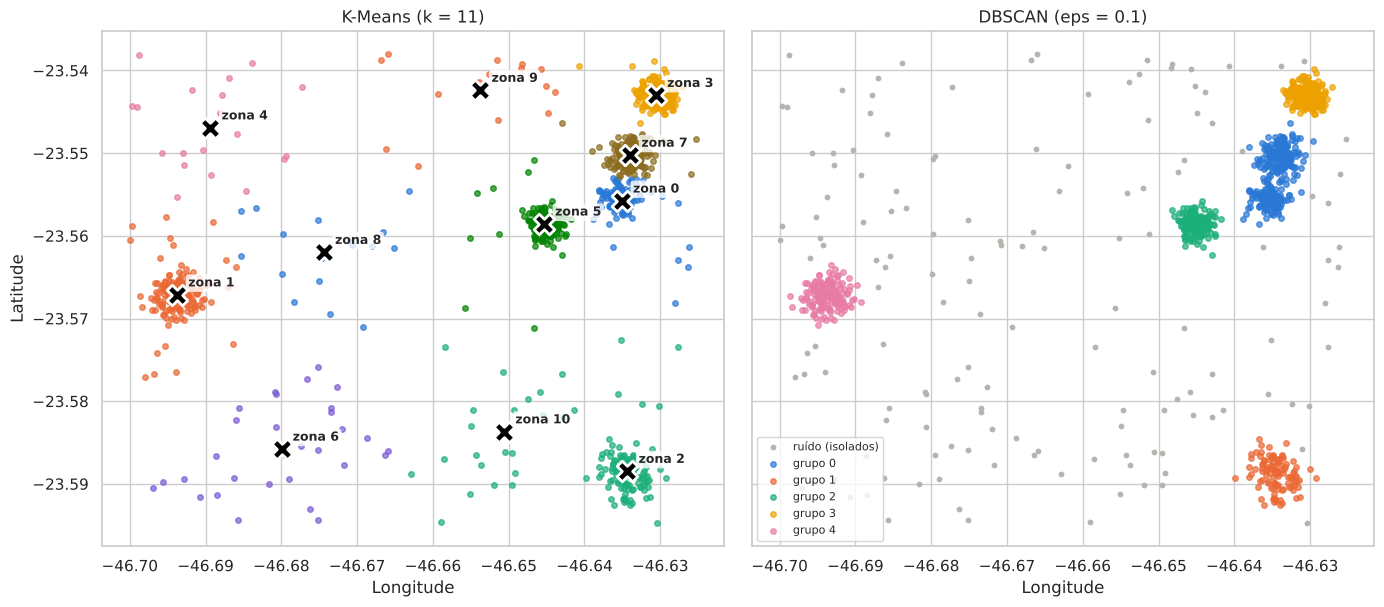

In [16]:
EPS = 0.10
df["grupo_dbscan"] = DBSCAN(eps=EPS, min_samples=10).fit_predict(X_esc)
n_db = df["grupo_dbscan"].nunique() - (1 if -1 in df["grupo_dbscan"].values else 0)
print(f"DBSCAN (eps={EPS}): {n_db} grupos | ruído: {(df['grupo_dbscan'] == -1).mean():.0%} dos relatos")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
paleta = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#7a5cd6", "#8c6d1f"]

for z in sorted(df["zona"].unique()):
    parte = df[df["zona"] == z]
    ax1.scatter(parte["longitude"], parte["latitude"], s=16, alpha=0.7, color=paleta[z % len(paleta)])
centros = escala.inverse_transform(kmeans.cluster_centers_)
ax1.scatter(centros[:, 1], centros[:, 0], marker="X", s=220, color="black", edgecolor="white", linewidth=2)
# com muitas zonas as cores se repetem, então escrevemos o número da zona ao lado de cada centro
for z, (lat_c, lon_c) in enumerate(centros):
    ax1.annotate(f"zona {z}", (lon_c, lat_c), xytext=(8, 6), textcoords="offset points", fontsize=9, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))
ax1.set_title(f"K-Means (k = {K})")

for g in sorted(df["grupo_dbscan"].unique()):
    parte = df[df["grupo_dbscan"] == g]
    if g == -1:
        ax2.scatter(parte["longitude"], parte["latitude"], s=10, color="#b5b5b0", label="ruído (isolados)")
    else:
        ax2.scatter(parte["longitude"], parte["latitude"], s=16, alpha=0.7, color=paleta[g % len(paleta)], label=f"grupo {g}")
ax2.set_title(f"DBSCAN (eps = {EPS})")

for ax in (ax1, ax2):
    ax.set_xlabel("Longitude")
    ax.set_aspect(1 / np.cos(np.radians(-23.56)))
ax2.legend(fontsize=8, loc="lower left")
ax1.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

### 4.3 Comparação e escolha

In [17]:
mascara = df["grupo_dbscan"] != -1
comparacao = pd.DataFrame([
    {"modelo": f"K-Means (k={K})", "grupos": K, "ruido": "0%",
     "silhouette": round(sil_kmeans, 3), "classifica ponto novo": "sim"},
    {"modelo": f"DBSCAN (eps={EPS})", "grupos": n_db, "ruido": f"{(~mascara).mean():.0%}",
     "silhouette": round(silhouette_score(X_esc[mascara], df.loc[mascara, "grupo_dbscan"]), 3),
     "classifica ponto novo": "não"},
])
comparacao

,modelo,grupos,ruido,silhouette,classifica ponto novo
0,K-Means (k=11),11,0%,0.679,sim
1,DBSCAN (eps=0.1),5,13%,0.745,não


**Interpretação da comparação:**
- Os dois algoritmos encontram **os mesmos focos** no mapa, o que aumenta a confiança de que as zonas são reais. O DBSCAN junta dois focos vizinhos do centro em um grupo só, porque eles ficam muito próximos.
- O **DBSCAN** tem uma vantagem: separa os **obstáculos isolados** como ruído (pontos cinza). Por isso o silhouette dele, calculado sem o ruído, fica mais alto.
- O **K-Means** não tem a ideia de "ruído": para cobrir os pontos espalhados, ele cria **zonas grandes e vazias** (os centros longe dos focos no gráfico da esquerda).
- Mas o DBSCAN **não tem `predict`**: ele não consegue dizer em qual grupo cai um **ponto novo** da rota, que é justamente o que a API precisa fazer.

**Escolha: K-Means** para a API. Para não perder a vantagem do DBSCAN, usamos duas regras na próxima seção:
1. cada zona tem um **raio**: um ponto fora dele **não está em zona crítica**;
2. zonas **grandes e vazias** (densidade muito baixa) são marcadas como **"Sem zona crítica"**. Elas fazem o mesmo papel do ruído do DBSCAN.

## 5. Avaliação: perfil e criticidade de cada zona

Para cada zona calculamos:
- **centro** (latitude/longitude) e **bairro predominante**;
- **quantidade de obstáculos** e **% de cada tipo**;
- **gravidade média**, com pesos pensados para quem usa cadeira de rodas:

| Tipo | Peso | Motivo |
|---|---|---|
| escada sem rampa | 3 | barreira intransponível |
| buraco | 3 | risco de queda e de travar a roda |
| calçada irregular | 2 | difícil e cansativo, mas às vezes passável |
| obstrução da calçada | 1 | geralmente dá para contornar |

- **raio da zona:** distância (em metros) do centro que inclui **80% dos relatos** da zona. Os 20% mais distantes costumam ser obstáculos isolados que o K-Means "puxou" para a zona. Usamos uma aproximação simples para converter graus em metros (1° de latitude ≈ 111 km).

**Índice de criticidade = densidade ponderada = (soma dos pesos dos obstáculos dentro do raio) ÷ (área da zona em km²).**

Em palavras: **quantos "pontos de gravidade" existem em cada km²**. Ele junta três coisas:
- **quantidade:** mais obstáculos → índice maior;
- **gravidade:** escadas e buracos pesam mais que obstruções;
- **concentração:** 100 obstáculos em 3 quarteirões são muito piores para quem anda de cadeira de rodas do que 100 obstáculos espalhados por um bairro inteiro.

In [18]:
PESOS = {"escada_sem_rampa": 3, "buraco": 3, "calcada_irregular": 2, "obstrucao_calcada": 1}

df["peso"] = df["tipo_obstaculo"].map(PESOS)
df["dist_centro_m"] = distancia_metros(df["latitude"], df["longitude"],
                                       centros[df["zona"], 0], centros[df["zona"], 1])

perfis = []
for z in range(K):
    parte = df[df["zona"] == z]
    raio = parte["dist_centro_m"].quantile(0.80)
    dentro = parte[parte["dist_centro_m"] <= raio]
    area_km2 = np.pi * (raio / 1000) ** 2
    perfil = {
        "zona": z,
        "centro_lat": round(centros[z, 0], 6),
        "centro_lon": round(centros[z, 1], 6),
        "bairro_predominante": parte["bairro"].mode()[0],
        "raio_m": int(round(raio)),
        "area_km2": round(area_km2, 3),
        "obstaculos": len(dentro),
        "gravidade_media": round(dentro["peso"].mean(), 2),
        "indice_criticidade": int(round(dentro["peso"].sum() / area_km2)),
        "tipo_mais_comum": dentro["tipo_obstaculo"].mode()[0],
    }
    for t in TIPOS:
        perfil[f"%_{t}"] = round((dentro["tipo_obstaculo"] == t).mean() * 100, 1)
    perfis.append(perfil)

perfis = pd.DataFrame(perfis)

**Níveis de criticidade.** Comparamos o índice de cada zona com o **maior** índice encontrado:
- **Alta:** ≥ 70% do maior índice;
- **Média:** de 40% a 70%;
- **Baixa:** de 10% a 40%;
- **Sem zona crítica:** abaixo de 10%. São as zonas grandes e vazias que o K-Means criou para cobrir os **obstáculos isolados**.

Usamos uma régua **relativa** porque não existe uma norma oficial de "quantos obstáculos tornam uma área crítica". Com dados reais, esses cortes poderiam ser definidos junto com a prefeitura ou com associações de pessoas com deficiência.

In [19]:
maior = perfis["indice_criticidade"].max()

def nivel(indice):
    if indice >= 0.70 * maior:
        return "Alta"
    if indice >= 0.40 * maior:
        return "Média"
    if indice >= 0.10 * maior:
        return "Baixa"
    return "Sem zona crítica"

perfis["nivel"] = perfis["indice_criticidade"].apply(nivel)
perfis["critica"] = perfis["nivel"] != "Sem zona crítica"
perfis = perfis.sort_values("indice_criticidade", ascending=False).reset_index(drop=True)
perfis[["zona", "bairro_predominante", "raio_m", "area_km2", "obstaculos", "gravidade_media", "indice_criticidade", "nivel",
        "tipo_mais_comum"] + [f"%_{t}" for t in TIPOS]]

,zona,bairro_predominante,raio_m,area_km2,obstaculos,gravidade_media,indice_criticidade,nivel,tipo_mais_comum,%_buraco,%_calcada_irregular,%_escada_sem_rampa,%_obstrucao_calcada
0,5,Bela Vista,229,0.164,137,2.47,2065,Alta,escada_sem_rampa,8.8,29.2,50.4,11.7
1,3,Sé,217,0.148,189,1.57,2001,Alta,obstrucao_calcada,11.6,23.3,5.3,59.8
2,7,Sé,245,0.189,151,2.09,1671,Alta,calcada_irregular,27.8,38.4,7.3,26.5
3,0,Liberdade,271,0.230,109,2.29,1085,Média,escada_sem_rampa,16.5,28.4,33.9,21.1
4,1,Pinheiros,339,0.361,135,2.34,877,Média,buraco,53.3,17.0,5.2,24.4
5,2,Vila Mariana,390,0.478,88,2.26,417,Baixa,calcada_irregular,29.5,55.7,5.7,9.1
6,6,Pinheiros,1220,4.677,24,2.29,12,Sem zona crítica,calcada_irregular,20.8,45.8,20.8,12.5
7,10,Vila Mariana,1051,3.471,18,2.28,12,Sem zona crítica,calcada_irregular,22.2,50.0,16.7,11.1
8,4,Pinheiros,1073,3.616,15,2.20,9,Sem zona crítica,calcada_irregular,26.7,66.7,0.0,6.7
9,8,Pinheiros,1114,3.901,13,2.15,7,Sem zona crítica,calcada_irregular,15.4,53.8,15.4,15.4


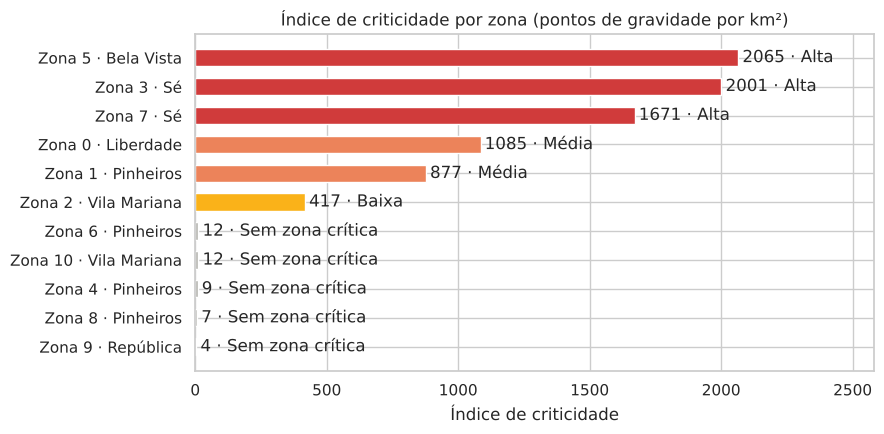

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
rotulos = [f"Zona {z} · {b}" for z, b in zip(perfis["zona"], perfis["bairro_predominante"])]
barras = ax.barh(rotulos, perfis["indice_criticidade"], color=[CORES_NIVEL.get(n, "#b5b5b0") for n in perfis["nivel"]], height=0.6)
ax.bar_label(barras, labels=[f"{i} · {n}" for i, n in zip(perfis["indice_criticidade"], perfis["nivel"])], padding=3)
ax.invert_yaxis()
ax.set_xlim(0, maior * 1.25)
ax.set_title("Índice de criticidade por zona (pontos de gravidade por km²)")
ax.set_xlabel("Índice de criticidade")
plt.tight_layout()
plt.show()

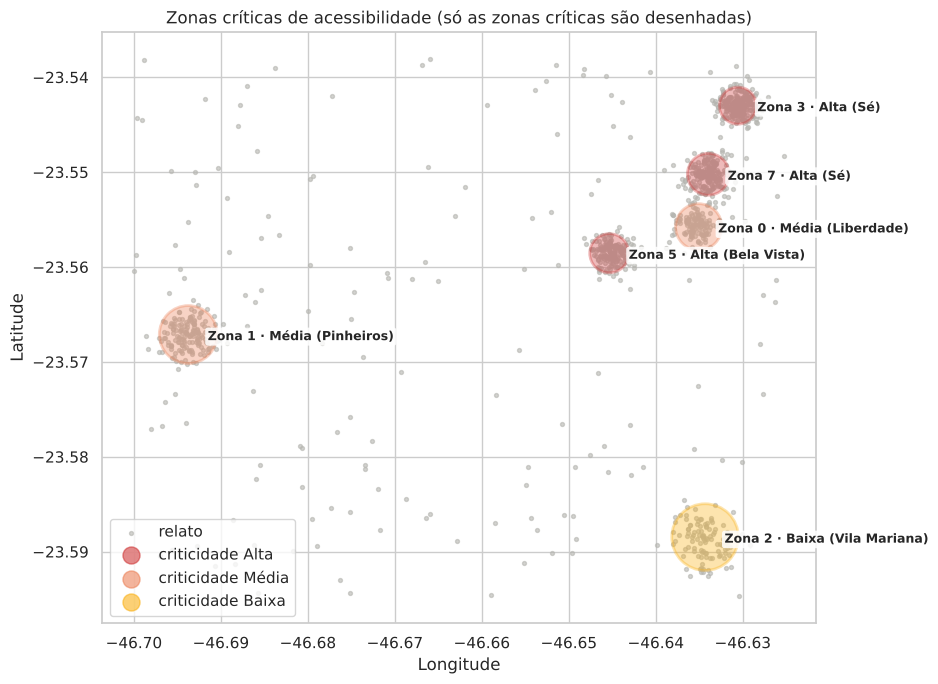

In [21]:
# mapa final: zonas com o raio e a cor do nível
fig, ax = plt.subplots(figsize=(10, 7))
from matplotlib.patches import Ellipse

ax.scatter(df["longitude"], df["latitude"], s=8, color="#b5b5b0", alpha=0.6, label="relato")
for _, p in perfis[perfis["critica"]].iterrows():
    # raio em graus (elipse por causa da diferença entre graus de lat e lon)
    elipse = Ellipse((p["centro_lon"], p["centro_lat"]),
                     width=2 * p["raio_m"] / METROS_POR_GRAU_LON, height=2 * p["raio_m"] / METROS_POR_GRAU_LAT,
                     facecolor=CORES_NIVEL[p["nivel"]], alpha=0.35, edgecolor=CORES_NIVEL[p["nivel"]], linewidth=2)
    ax.add_patch(elipse)
    ax.annotate(f"Zona {p['zona']} · {p['nivel']} ({p['bairro_predominante']})",
                (p["centro_lon"], p["centro_lat"]), xytext=(14, -4), textcoords="offset points",
                fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.85))
for n, cor in CORES_NIVEL.items():
    ax.scatter([], [], s=150, color=cor, alpha=0.6, label=f"criticidade {n}")
ax.set_title("Zonas críticas de acessibilidade (só as zonas críticas são desenhadas)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.radians(-23.56)))
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

**Interpretação das zonas** (veja a tabela e o mapa):
- **Escadaria do Bixiga (Bela Vista) tem a criticidade mais alta**, mesmo **não** sendo a zona com mais relatos. Metade dos obstáculos são **escadas sem rampa** (peso 3), em uma área pequena. Para um cadeirante, é a área mais difícil do mapa.
- **Rua 25 de Março e Praça da Sé** também são **Alta**: são as zonas com **mais relatos**. Na 25 de Março predomina a **obstrução da calçada** (comércio de rua); na Sé, a **calçada irregular**.
- **Liberdade** (muitas escadas e ladeiras) e **Largo da Batata** em Pinheiros (mais da metade são **buracos**) ficam em **Média**.
- **Vila Mariana** é **Baixa**: tem relatos, mas mais espalhados (raio maior) e principalmente de calçada irregular.
- As **5 zonas restantes** são grandes e quase vazias, e ficam como **"Sem zona crítica"**: são os obstáculos isolados.
- O **tipo mais comum** muda de zona para zona, o que permite ao app dar **avisos específicos**: "trecho com escadas sem rampa" é diferente de "calçada ocupada por comércio".

**Limitação:** o K-Means não "sabe" que existem obstáculos isolados. Por isso o raio de 80% e a checagem de distância na API são importantes.

### 5.1 Testando com pontos novos
Simulamos o que a API vai fazer: recebe um ponto, descobre a zona mais próxima com o K-Means e confere se o ponto está **dentro do raio**.

In [22]:
from sklearn.pipeline import Pipeline

# o Pipeline junta a padronização e o K-Means já treinados: recebe [lat, lon] "crus"
pipeline_zonas = Pipeline([("escala", escala), ("kmeans", kmeans)])
perfil_por_zona = perfis.set_index("zona")

def consultar_ponto(lat, lon):
    zona = int(pipeline_zonas.predict(pd.DataFrame([[lat, lon]], columns=["latitude", "longitude"]).values)[0])
    p = perfil_por_zona.loc[zona]
    distancia = distancia_metros(lat, lon, p["centro_lat"], p["centro_lon"])
    em_zona_critica = bool(p["critica"]) and bool(distancia <= p["raio_m"])
    return {"zona": zona, "em_zona_critica": em_zona_critica, "distancia_m": int(distancia),
            "nivel": p["nivel"] if em_zona_critica else "Sem zona crítica"}

pontos_teste = {
    "Praça da Sé": (-23.5503, -46.6340),
    "Escadaria do Bixiga": (-23.5585, -46.6450),
    "Parque Ibirapuera (longe de tudo)": (-23.5874, -46.6576),
}
for nome, (lat, lon) in pontos_teste.items():
    print(f"{nome:35s} -> {consultar_ponto(lat, lon)}")

Praça da Sé                         -> {'zona': 7, 'em_zona_critica': True, 'distancia_m': 8, 'nivel': 'Alta'}
Escadaria do Bixiga                 -> {'zona': 5, 'em_zona_critica': True, 'distancia_m': 35, 'nivel': 'Alta'}
Parque Ibirapuera (longe de tudo)   -> {'zona': 10, 'em_zona_critica': False, 'distancia_m': 823, 'nivel': 'Sem zona crítica'}


**Resultado:** pontos dentro dos focos recebem a zona e o nível. O ponto longe de todos os focos (Parque Ibirapuera) cai em uma zona "grande e vazia" do K-Means, e por isso a resposta é **"Sem zona crítica"**. É assim que evitamos alarmes falsos.

## 6. Exportação do modelo
Salvamos com o `joblib`:
- o **Pipeline** (padronização + K-Means), que recebe latitude e longitude "cruas";
- a **tabela de perfil das zonas** (centro, raio, nível, tipos);
- os **pesos** e a forma de conversão para metros, para a API calcular a distância do mesmo jeito.

In [23]:
pacote = {
    "pipeline": pipeline_zonas,
    "variaveis": ["latitude", "longitude"],
    "perfis": perfis.to_dict(orient="records"),
    "pesos": PESOS,
    "metros_por_grau_lat": METROS_POR_GRAU_LAT,
    "metros_por_grau_lon": float(METROS_POR_GRAU_LON),
    "metricas": {"k": K, "silhouette": round(float(sil_kmeans), 4)},
}
os.makedirs(PASTA_MODELOS, exist_ok=True)
caminho = os.path.join(PASTA_MODELOS, "zonas_criticas.joblib")
joblib.dump(pacote, caminho)
print("Modelo salvo em", caminho, f"({os.path.getsize(caminho) / 1e3:.0f} KB)")

# conferência: carregar e prever um ponto
carregado = joblib.load(caminho)
print("Zona prevista para a Praça da Sé:", carregado["pipeline"].predict([[-23.5503, -46.6340]])[0])

Modelo salvo em ../modelos/zonas_criticas.joblib (8 KB)
Zona prevista para a Praça da Sé: 7


## Resumo do Modelo 2
| Item | Resultado |
|---|---|
| Dados | `relatos_obstaculos.csv` (sintético, documentado), 1.132 linhas → 1.117 após remover duplicados |
| Variáveis | latitude e longitude padronizadas (o tipo é usado para descrever e pesar as zonas) |
| Modelos comparados | K-Means (cotovelo + silhouette) e DBSCAN (zonas + ruído) |
| Escolhido | K-Means, porque classifica pontos novos (necessário na API) |
| Escolha do k | Silhouette + regra prática (raio mediano ≤ 500 m) |
| Avaliação | Silhouette, perfil de cada zona e nível de criticidade (Alta/Média/Baixa/Sem zona crítica) por densidade ponderada |
| Exportação | `modelos/zonas_criticas.joblib` (Pipeline + perfis + raios) |